# EDA profundo: qué puede mejorar el primer semestre de 2025

El tablero privado mide las semanas 1 a 26 de 2025, pronosticadas desde la última semana de 2024. Este cuaderno busca en los datos lo que puede bajar ese error. No entrena modelos: usa los datos, las bases por horizonte (B) en walk-forward y las predicciones walk-forward de las redes de `2026-11-04-red-dinamica-h1`.

Secciones:

1. Dónde está el error.
2. Cuánto del error es ruido semanal.
3. Estacionalidad por región.
4. El año siguiente a un brote.
5. Clima a escala de trimestre y año.
6. Calendario: lotes de reporte, Semana Santa y año nuevo.
7. Errores de B y de la mezcla con red, por región y horizonte.
8. Conclusiones.

In [1]:
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)


def raiz_repo():
    aqui = Path.cwd().resolve()
    for carpeta in [aqui, *list(aqui.parents)[:5]]:
        if (carpeta / "data" / "train.parquet").exists():
            return carpeta
    raise FileNotFoundError("No se encontro data/train.parquet.")


RAIZ = raiz_repo()
RED = RAIZ / "ensayos/juan/2026-11-04-red-dinamica-h1"
train = pd.read_parquet(RAIZ / "data/train.parquet").sort_values(["id_departamento", "anio", "semana"])
test = pd.read_parquet(RAIZ / "data/test.parquet").sort_values(["id_departamento", "anio", "semana"])
B = pd.read_parquet(RED / "b_walkforward.parquet")
redes = pd.read_parquet(RED / "predicciones_final5.parquet")
nombre = train.drop_duplicates("id_departamento").set_index("id_departamento").departamento
COSTA = [4, 5, 11, 13, 16, 19, 28]  # Atlantico, Bolivar, Cesar, Cordoba, Guajira, Magdalena, Sucre
piv = train[train.semana <= 52].pivot_table(index=["id_departamento", "anio"], columns="semana", values="casos_dengue")
anual = piv.mean(axis=1).unstack()
print("Departamentos:", train.id_departamento.nunique(), "| años:", train.anio.min(), "-", train.anio.max())

Departamentos: 31 | años: 2007 - 2024


## 1. Dónde está el error

El MSE eleva al cuadrado los casos, así que pocos departamentos grandes deciden el puntaje. Se mide la parte del error de B en el primer semestre (walk-forward 2014-2023) que aporta cada departamento, y la parte de la diferencia entre las dos selecciones finales en 2025 (dónde está el riesgo de escenario).

,departamento,parte_del_error_B,parte_del_riesgo_2025,media_2024
30,Valle Del Cauca,0.394,0.266,1705.981
2,Antioquia,0.145,0.074,336.154
20,Meta,0.127,0.000,154.000
29,Tolima,0.073,0.069,481.385
18,Huila,0.051,0.002,387.212
27,Santander,0.046,0.265,692.269
4,Atlantico,0.034,0.000,155.577
22,Norte De Santander,0.022,0.000,161.231
9,Casanare,0.018,0.000,64.481
5,Bolivar,0.016,0.076,246.596


Los 6 primeros suman 0.84 del error de B


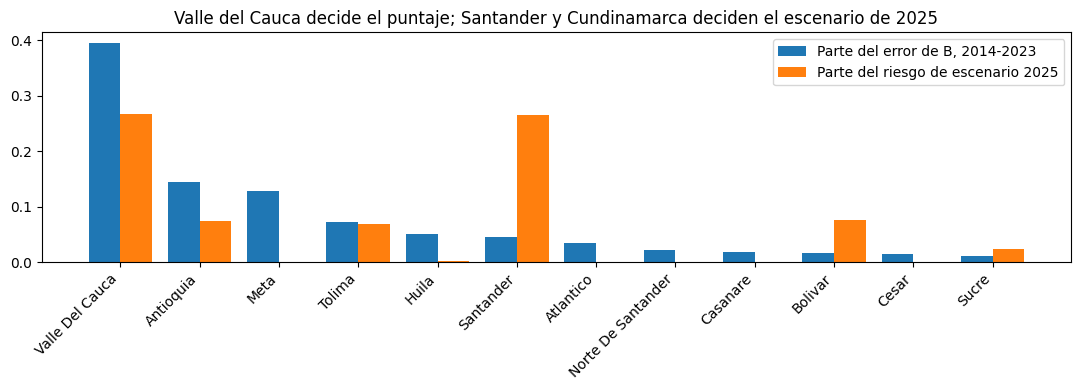

In [2]:
h1 = B[(B.semana <= 26) & B.anio.between(2014, 2023)].copy()
h1["e2"] = (h1.b - h1.y) ** 2
cuota = h1.groupby("id_departamento").e2.sum() / h1.e2.sum()
mezcla = pd.read_csv(RAIZ / "entrega/submission_mezcla_red.csv")
continuidad = pd.read_csv(RAIZ / "entrega/submission_continuidad_red.csv")
partes = mezcla.id.str.split("_", expand=True).astype(int)
dif = pd.DataFrame({"d": partes[0], "s": partes[2], "dif2": (mezcla.dengue - continuidad.dengue) ** 2})
riesgo = dif[dif.s <= 26].groupby("d").dif2.sum() / dif[dif.s <= 26].dif2.sum()
tabla = pd.DataFrame({"departamento": nombre, "parte_del_error_B": cuota, "parte_del_riesgo_2025": riesgo, "media_2024": anual[2024]})
tabla = tabla.sort_values("parte_del_error_B", ascending=False)
display(tabla.head(12).round(3))
print("Los 6 primeros suman", round(tabla.parte_del_error_B.head(6).sum(), 2), "del error de B")

fig, ax = plt.subplots(figsize=(11, 4))
top = tabla.head(12)
x = np.arange(len(top))
ax.bar(x - 0.2, top.parte_del_error_B, width=0.4, label="Parte del error de B, 2014-2023")
ax.bar(x + 0.2, top.parte_del_riesgo_2025.fillna(0), width=0.4, label="Parte del riesgo de escenario 2025")
ax.set_xticks(x)
ax.set_xticklabels(top.departamento, rotation=45, ha="right")
ax.set_title("Valle del Cauca decide el puntaje; Santander y Cundinamarca deciden el escenario de 2025")
ax.legend()
plt.tight_layout()
plt.show()

**Hallazgo.** Valle del Cauca aporta cerca del 40 % del error de B en el primer semestre y seis departamentos del interior (Valle, Antioquia, Meta, Tolima, Huila y Santander) más del 80 %. La Costa pesa poco en el error histórico. El riesgo de 2025 está en Valle, Santander y Cundinamarca: ahí las dos selecciones finales más se separan.

## 2. Cuánto del error es ruido semanal

Una parte del error no la puede quitar ningún pronóstico suave: los saltos de una semana a otra (lotes de reporte, festivos, retrasos). Se estima como el MSE de cada semana contra la mediana móvil de 5 semanas de la propia serie real, y se compara con el error de B.

In [3]:
serie = train[train.semana <= 52].sort_values(["id_departamento", "anio", "semana"]).copy()
serie["suave"] = serie.groupby("id_departamento").casos_dengue.transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
serie["ruido2"] = (serie.casos_dengue - serie.suave) ** 2
ruido = serie[serie.semana <= 26].groupby("anio").ruido2.mean()
error_b = h1.groupby("anio").e2.mean()
comparacion = pd.DataFrame({"error_B_semestre_1": error_b, "ruido_semanal": ruido.loc[2014:2023]})
comparacion["parte_ruido"] = comparacion.ruido_semanal / comparacion.error_B_semestre_1
display(comparacion.round(2).T)
print("Media 2014-2023: error de B", round(comparacion.error_B_semestre_1.mean()), "| ruido", round(comparacion.ruido_semanal.mean()))

anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
error_B_semestre_1,1418.90,2647.18,9742.67,1120.22,415.57,4886.16,8399.03,581.33,1021.41,5108.56
ruido_semanal,332.02,811.34,2305.09,89.62,178.91,1092.13,3417.69,527.68,389.62,2051.81
parte_ruido,0.23,0.31,0.24,0.08,0.43,0.22,0.41,0.91,0.38,0.40


Media 2014-2023: error de B 3534 | ruido 1120


**Hallazgo.** Cerca de un tercio del error de B en el primer semestre es ruido semanal que un pronóstico suave no puede capturar. Los otros dos tercios son de nivel y de forma: ahí está lo que se puede mejorar. El único ruido que sí se puede anticipar es el de los lotes de reporte, que ya entra con la amplitud medida por el sensor.

## 3. Estacionalidad por región

Perfil semanal de cada departamento en años sin brote (media anual menor que 2 veces su mediana), dividido por su media. Se agrupa en Costa, Valle del Cauca, Andino del centro y sur (Tolima, Huila, Cundinamarca) y Llanos (Meta, Casanare).

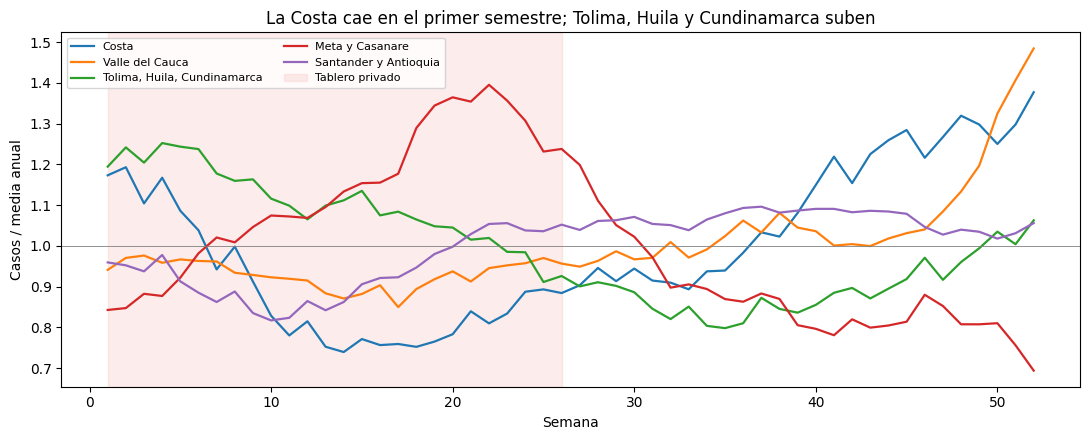

,departamento,semanas_1_13,semanas_14_26,semanas_45_52,primer_semestre_sobre_diciembre
30,Valle Del Cauca,0.94,0.92,1.21,0.77
2,Antioquia,0.91,0.93,1.06,0.87
20,Meta,1.01,1.19,0.86,1.27
29,Tolima,1.23,0.97,1.00,1.10
18,Huila,1.19,1.04,0.99,1.13
27,Santander,0.86,1.04,1.02,0.93
4,Atlantico,0.99,0.67,1.59,0.52
22,Norte De Santander,0.97,0.90,1.22,0.76
9,Casanare,0.95,1.35,0.74,1.55
5,Bolivar,0.94,0.83,1.20,0.74


In [4]:
normal = anual.le(2.0 * anual.median(axis=1).values[:, None])
perfiles = {}
for d in anual.index:
    anios = [a for a in anual.columns if normal.loc[d, a]]
    p = piv.loc[[(d, a) for a in anios]].mean()
    p = p.rolling(5, center=True, min_periods=1).mean()
    perfiles[d] = p / p.mean()
perfiles = pd.DataFrame(perfiles).T
grupos = {
    "Costa": COSTA,
    "Valle del Cauca": [30],
    "Tolima, Huila, Cundinamarca": [29, 18, 14],
    "Meta y Casanare": [20, 9],
    "Santander y Antioquia": [27, 2],
}
fig, ax = plt.subplots(figsize=(11, 4.5))
for etiqueta, deptos in grupos.items():
    ax.plot(perfiles.columns, perfiles.loc[deptos].mean(), lw=1.6, label=etiqueta)
ax.axhline(1, color="grey", lw=0.6)
ax.axvspan(1, 26, color="#F5B7B1", alpha=0.25, label="Tablero privado")
ax.set_xlabel("Semana")
ax.set_ylabel("Casos / media anual")
ax.set_title("La Costa cae en el primer semestre; Tolima, Huila y Cundinamarca suben")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
resumen = pd.DataFrame({
    "departamento": nombre,
    "semanas_1_13": perfiles.loc[:, 1:13].mean(axis=1),
    "semanas_14_26": perfiles.loc[:, 14:26].mean(axis=1),
    "semanas_45_52": perfiles.loc[:, 45:52].mean(axis=1),
})
resumen["primer_semestre_sobre_diciembre"] = perfiles.loc[:, 1:26].mean(axis=1) / resumen.semanas_45_52
display(resumen.loc[tabla.index[:12]].round(2))

**Hallazgo.** En un año normal la Costa tiene su pico en noviembre y diciembre y su mínimo en abril y mayo: el primer semestre queda en 0,5 a 0,8 veces diciembre (Atlántico 0,52). Tolima, Huila y Cundinamarca hacen lo contrario, con el pico entre enero y mayo. Valle del Cauca tiene el pico en la semana 52 y el mínimo en la 17. Un ajuste al nivel de diciembre tiene que respetar esa forma por región: no es lo mismo arrancar alto en Atlántico que en Tolima.

## 4. El año siguiente a un brote

Para cada departamento y año con brote (media anual mayor que 2 veces la mediana de los 6 años previos) se mide el primer semestre siguiente como fracción del nivel de diciembre sin picos (mediana de las semanas 45 a 52). La última fila de cada departamento es 2024, el caso que hay que pronosticar.

,departamento,anio,exceso,semana_pico,pico_sobre_diciembre,diciembre,semanas_1_4,semanas_1_13,semanas_14_26,semanas_27_52
0,Antioquia,2010,18.92,24,8.48,115.5,0.47,0.34,0.37,0.30
1,Antioquia,2013,2.93,24,1.31,100.0,1.27,1.02,0.96,1.49
2,Antioquia,2014,2.92,39,1.40,130.0,1.16,0.84,0.71,1.21
3,Antioquia,2016,4.57,36,2.33,315.5,0.40,0.31,0.27,0.23
4,Antioquia,2024,6.07,32,1.54,310.5,NaN,NaN,NaN,NaN
5,Atlantico,2013,2.56,25,1.11,152.0,1.35,0.86,0.50,0.92
6,Atlantico,2021,2.56,48,1.20,376.0,0.51,0.40,0.28,0.70
7,Atlantico,2022,3.48,52,0.93,454.0,0.50,0.34,0.13,0.23
8,Bolivar,2010,3.25,43,1.25,48.5,0.53,0.36,0.24,0.21
9,Bolivar,2012,2.15,26,1.38,32.5,1.95,2.21,2.99,2.61


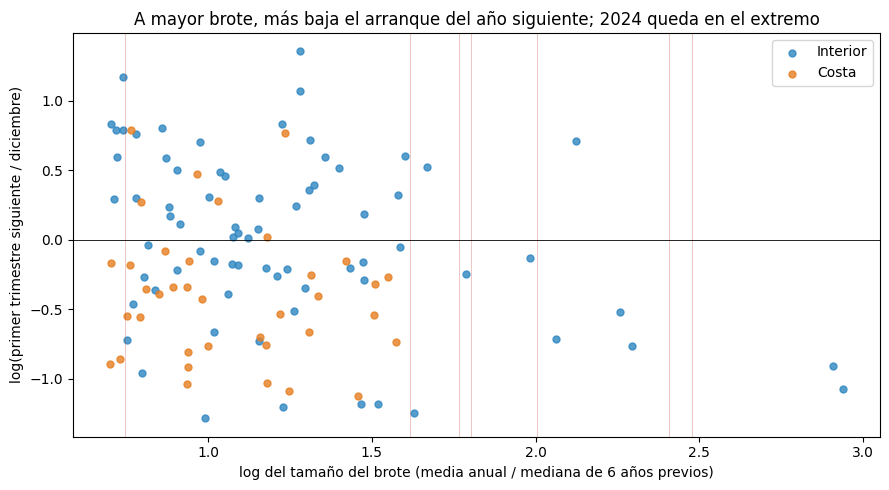

Correlación entre tamaño del brote y arranque siguiente: -0.22


In [5]:
filas = []
for d in anual.index:
    for a in range(2009, 2025):
        previos = [x for x in range(a - 6, a) if x >= 2007]
        base = np.median(anual.loc[d, previos])
        if base < 5 or anual.loc[d, a] / base < 2.0:
            continue
        s = piv.loc[(d, a)]
        L = s.loc[45:52].median()
        m4 = s.rolling(4).mean()
        fila = {"departamento": nombre[d], "anio": a, "exceso": anual.loc[d, a] / base, "semana_pico": int(m4.idxmax()),
                "pico_sobre_diciembre": m4.max() / max(L, 1), "diciembre": L}
        if (d, a + 1) in piv.index:
            n = piv.loc[(d, a + 1)]
            fila.update({"semanas_1_4": n.loc[1:4].mean() / L, "semanas_1_13": n.loc[1:13].mean() / L,
                         "semanas_14_26": n.loc[14:26].mean() / L, "semanas_27_52": n.loc[27:52].mean() / L})
        filas.append(fila)
brotes = pd.DataFrame(filas)
grandes = ["Valle Del Cauca", "Santander", "Antioquia", "Tolima", "Cundinamarca", "Huila", "Bolivar", "Atlantico", "Meta"]
display(brotes[brotes.departamento.isin(grandes)].sort_values(["departamento", "anio"]).round(2).reset_index(drop=True))

h = brotes.dropna(subset=["semanas_1_13"]).copy()
h["costa"] = h.departamento.isin(nombre.loc[COSTA].values)
fig, ax = plt.subplots(figsize=(9, 5))
for es_costa, color, etiqueta in [(False, "#2E86C1", "Interior"), (True, "#E67E22", "Costa")]:
    p = h[h.costa == es_costa]
    ax.scatter(np.log(p.exceso), np.log(p.semanas_1_13), color=color, s=25, alpha=0.8, label=etiqueta)
for _, f in brotes[(brotes.anio == 2024) & brotes.departamento.isin(grandes)].iterrows():
    ax.axvline(np.log(f.exceso), color="#C0392B", lw=0.5, alpha=0.4)
    ax.annotate(f.departamento.split()[0], (np.log(f.exceso), 1.6), rotation=90, fontsize=7, color="#C0392B")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("log del tamaño del brote (media anual / mediana de 6 años previos)")
ax.set_ylabel("log(primer trimestre siguiente / diciembre)")
ax.set_title("A mayor brote, más baja el arranque del año siguiente; 2024 queda en el extremo")
ax.legend()
plt.tight_layout()
plt.show()
print("Correlación entre tamaño del brote y arranque siguiente:", round(np.corrcoef(np.log(h.exceso), np.log(h.semanas_1_13))[0, 1], 2))

**Hallazgo.** El tamaño del brote se asocia con el arranque del año siguiente, aunque de forma débil (r = -0,22): a mayor brote, más baja el primer trimestre frente a diciembre. 2024 fue el brote más grande del registro en Valle del Cauca, Santander y Antioquia, lo que empuja hacia la caída. Los análogos por departamento no apuntan todos al mismo lado: Valle del Cauca después de 2010 y de 2013 quedó en 0,47-0,49 veces diciembre en el primer trimestre (unos 250 casos en 2025); Antioquia después de 2010 y de 2016, en 0,31-0,34 (unos 100); Atlántico después de los cierres altos de 2021 y 2022, en 0,34-0,40 (unos 100). Tolima y Cundinamarca, en cambio, se quedaron cerca de 0,8-0,9.

Una regresión con estos rasgos (forma estacional, tamaño del brote, nivel de diciembre, caída desde el pico) no le gana a B en walk-forward. Sirven como contexto y como variables para las redes, no como reemplazo de B.

## 5. Clima a escala de trimestre y año

La correlación semanal del clima con los casos dentro de cada departamento es débil (sección 1 del cuaderno de entrega). Aquí se mira la escala gruesa: la anomalía de temperatura de cada trimestre, a nivel nacional, contra la incidencia del año.

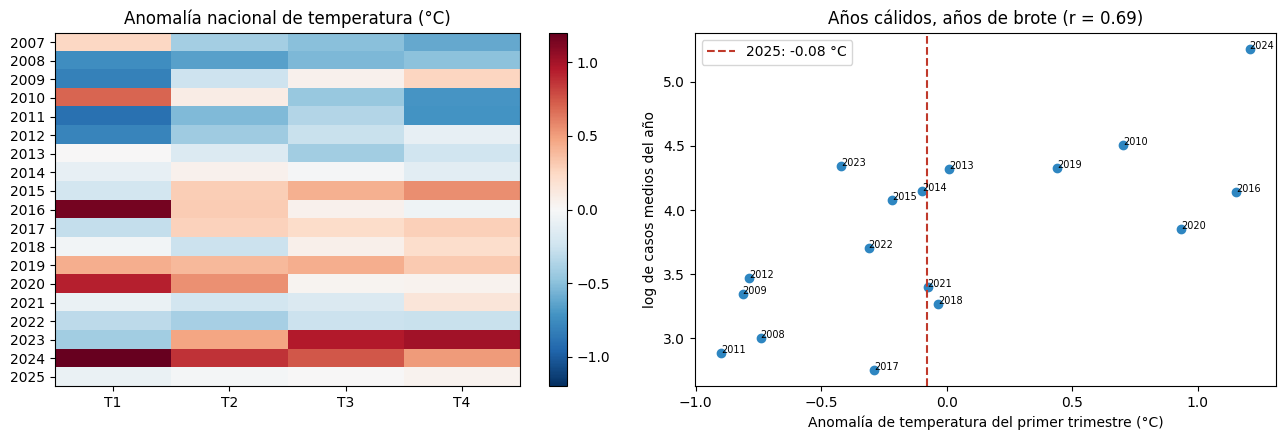

,temp_T4_previo,temp_T1,lluvia_T1,casos_medios
anio,,,,
2010,0.26,0.70,-1.22,90.75
2011,-0.71,-0.90,4.31,17.89
2016,0.56,1.15,-9.91,62.79
2017,-0.05,-0.29,3.67,15.67
2019,0.21,0.44,-1.92,75.89
2020,0.32,0.93,-10.82,46.99
2021,0.05,-0.08,4.16,29.97
2024,1.00,1.21,-6.50,191.67
2025,0.51,-0.08,10.89,NaN


In [6]:
full = pd.concat([train, test], ignore_index=True)
full = full[full.semana <= 52]
climatologia = full[full.anio <= 2024].groupby(["id_departamento", "semana"])[["temp_media_C", "precip_chirps_mm"]].mean()
indice = pd.MultiIndex.from_arrays([full.id_departamento, full.semana])
full["anom_temp"] = full.temp_media_C.to_numpy() - climatologia.temp_media_C.reindex(indice).to_numpy()
full["anom_lluvia"] = full.precip_chirps_mm.to_numpy() - climatologia.precip_chirps_mm.reindex(indice).to_numpy()
full["trimestre"] = np.select([full.semana <= 13, full.semana <= 26, full.semana <= 39], ["T1", "T2", "T3"], "T4")
temp = full.groupby(["anio", "trimestre"]).anom_temp.mean().unstack()
lluvia = full.groupby(["anio", "trimestre"]).anom_lluvia.mean().unstack()
incidencia = train[train.semana <= 52].groupby("anio").casos_dengue.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
image = axes[0].imshow(temp.to_numpy(), cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
axes[0].set_yticks(range(len(temp)))
axes[0].set_yticklabels(temp.index)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(temp.columns)
axes[0].set_title("Anomalía nacional de temperatura (°C)")
fig.colorbar(image, ax=axes[0])
x = temp.loc[2008:2024, "T1"]
y = np.log(incidencia.loc[2008:2024])
axes[1].scatter(x, y, color="#2E86C1")
for anio in x.index:
    axes[1].annotate(str(anio), (x[anio], y[anio]), fontsize=7)
axes[1].axvline(temp.loc[2025, "T1"], color="#C0392B", ls="--", label=f"2025: {temp.loc[2025, 'T1']:+.2f} °C")
axes[1].set_xlabel("Anomalía de temperatura del primer trimestre (°C)")
axes[1].set_ylabel("log de casos medios del año")
axes[1].set_title(f"Años cálidos, años de brote (r = {np.corrcoef(x, y)[0, 1]:.2f})")
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({"temp_T4_previo": temp.T4.shift(1), "temp_T1": temp.T1, "lluvia_T1": lluvia.T1, "casos_medios": incidencia}).loc[[2010, 2011, 2016, 2017, 2019, 2020, 2021, 2024, 2025]].round(2))

**Hallazgo.** A escala nacional los años de brote coinciden con primeros trimestres cálidos (El Niño): 2010, 2016, 2019-2020 y 2024. Los años que siguieron a un brote y se enfriaron cayeron: 2011 y 2017. El primer trimestre de 2025 está en la media (1,3 °C más frío que el de 2024) y es el más lluvioso del registro. Eso apoya una caída en 2025 frente al escenario de continuidad.

La señal no baja al departamento: dentro de cada departamento y año, la anomalía de temperatura casi no se correlaciona con el arranque del año siguiente (r cercano a 0,1). Con solo 4 o 5 brotes en la historia, es una pista de escenario, no una variable para entrenar.

## 6. Calendario: lotes de reporte, Semana Santa y año nuevo

La semana del primer miércoles de cada mes puede cargar un lote de reporte. Se mide, para cada año y mes, la razón entre esa semana y la mediana móvil de 5 semanas, sumando el país. Luego se miden la Semana Santa (fecha móvil) y la semana de año nuevo.

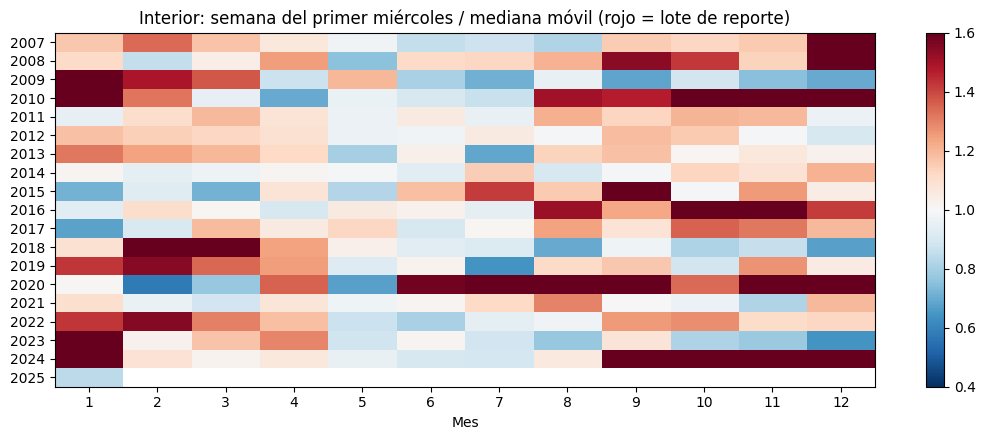

Semana Santa / semanas vecinas, mediana 2007-2024: 0.9 | rango 0.43 - 1.52 | en 2025 es la semana 15


In [7]:
semanal = train.sort_values(["id_departamento", "semana_inicio"]).copy()
semanal["base"] = semanal.groupby("id_departamento").casos_dengue.transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
miercoles = semanal.semana_inicio + pd.Timedelta(days=2)
semanal["lote"] = miercoles.dt.day <= 7
semanal["mes"] = miercoles.dt.month
semanal["anio_mes"] = miercoles.dt.year
interior = ~semanal.id_departamento.isin(COSTA)
lotes = semanal[semanal.lote & interior].groupby(["anio_mes", "mes"]).apply(lambda g: g.casos_dengue.sum() / max(g.base.sum(), 1), include_groups=False).unstack()
fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(lotes.to_numpy(), cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
ax.set_yticks(range(len(lotes)))
ax.set_yticklabels(lotes.index)
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_xlabel("Mes")
ax.set_title("Interior: semana del primer miércoles / mediana móvil (rojo = lote de reporte)")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()


def pascua(y):
    a, b, c = y % 19, y // 100, y % 100
    d, e, f = b // 4, b % 4, (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = c // 4, c % 4
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    return date(y, (h + l - 7 * m + 114) // 31, ((h + l - 7 * m + 114) % 31) + 1)


nacional = train.groupby("semana_inicio").casos_dengue.sum().sort_index()
filas = []
for y in range(2007, 2025):
    lunes = pd.Timestamp(pascua(y)) - pd.Timedelta(days=6)
    i = nacional.index.get_loc(lunes)
    v = nacional.iloc[i - 2 : i + 4].to_numpy(float)
    filas.append({"anio": y, "semana_santa_sobre_vecinas": v[2] / np.mean([v[0], v[1], v[4], v[5]])})
santa = pd.DataFrame(filas).set_index("anio")
semana_santa_2025 = int(test[test.semana_inicio == pd.Timestamp(pascua(2025)) - pd.Timedelta(days=6)].semana.iloc[0])
print("Semana Santa / semanas vecinas, mediana 2007-2024:", round(santa.iloc[:, 0].median(), 2), "| rango", round(santa.iloc[:, 0].min(), 2), "-", round(santa.iloc[:, 0].max(), 2), "| en 2025 es la semana", semana_santa_2025)

**Hallazgo.** Los lotes de reporte aparecen por rachas: finales de 2010, finales de 2016, comienzos de 2018, 2020 y comienzos de 2021, y desde septiembre de 2024. La racha de 2020 pasó a 2021 con otro calendario. El sensor del tablero público mostró que la de 2024 siguió en el segundo semestre de 2025 con cerca del 29 % de su fuerza: lo razonable es que en el primer semestre estuviera igual o más fuerte, no más débil.

Semana Santa baja la semana en torno a 10 % en la mediana, pero con mucha dispersión, y año nuevo no tiene un rebote sistemático. Su efecto en el MSE es despreciable frente al del nivel.

## 7. Errores de B y de la mezcla con red

Con las predicciones walk-forward de las redes (2 semillas) se descompone el error del primer semestre de 2014-2023 por región, departamento y bloque de semanas. La mezcla es 25 % TCN + 25 % MLP + 50 % B.

Aporte al MSE medio del primer semestre, por región


,e_b,e_mezcla,e_tcn,e_mlp
region,,,,
Costa,330.0,373.0,723.0,412.0
Interior,3204.0,2943.0,3073.0,3183.0


Sesgo medio (pronóstico - real), casos por departamento y semana


s_b          s_mezcla         
region Costa Interior    Costa Interior
bloque                                 
1-4     -4.7     -5.6      1.3     -1.6
5-8      4.3     -7.4      9.2     -3.0
9-13     8.0     -6.1     13.2     -2.0
14-19    2.3     -7.7      9.5     -3.4
20-26    2.7    -10.5      9.0     -6.4

,e_b,e_mezcla,departamento,cambio
id_departamento,,,,
30,1393.0,1207.0,Valle Del Cauca,-186.0
2,512.0,501.0,Antioquia,-12.0
20,450.0,447.0,Meta,-3.0
29,257.0,211.0,Tolima,-45.0
18,181.0,191.0,Huila,11.0
27,162.0,134.0,Santander,-28.0
4,121.0,172.0,Atlantico,51.0
22,78.0,94.0,Norte De Santander,16.0
9,65.0,66.0,Casanare,1.0


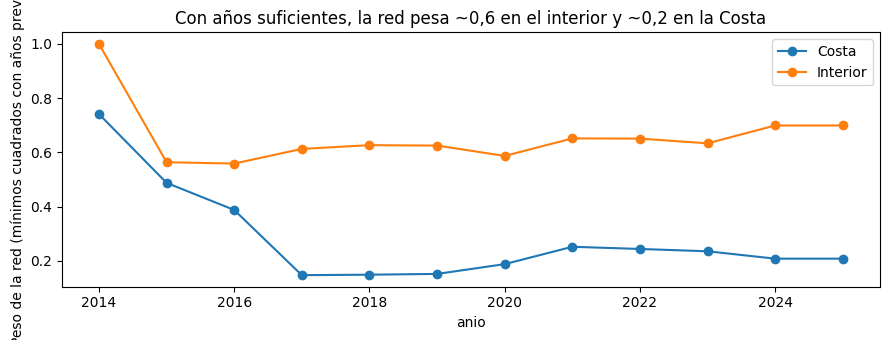

anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Costa,0.74,0.49,0.39,0.15,0.15,0.15,0.19,0.25,0.24,0.24,0.21,0.21
Interior,1.00,0.56,0.56,0.61,0.63,0.63,0.59,0.65,0.65,0.63,0.70,0.70


In [8]:
W = redes[redes.familia.isin(["tcn", "mlp"])].pivot_table(index=["anio", "id_departamento", "semana"], columns="familia", values="pred").reset_index()
W = W.merge(B[B.semana <= 26], on=["anio", "id_departamento", "semana"])
W["red"] = 0.5 * W.tcn + 0.5 * W.mlp
W["mezcla"] = 0.5 * W.red + 0.5 * W.b
W["region"] = np.where(W.id_departamento.isin(COSTA), "Costa", "Interior")
E = W[W.anio.between(2014, 2023)].copy()
for c in ["b", "mezcla", "tcn", "mlp"]:
    E["e_" + c] = (E[c] - E.y) ** 2
    E["s_" + c] = E[c] - E.y
por_region = E.groupby("region")[["e_b", "e_mezcla", "e_tcn", "e_mlp"]].sum() / (806 * 10)
print("Aporte al MSE medio del primer semestre, por región")
display(por_region.round(0))
E["bloque"] = pd.cut(E.semana, [0, 4, 8, 13, 19, 26], labels=["1-4", "5-8", "9-13", "14-19", "20-26"])
sesgo = E.groupby(["region", "bloque"], observed=True)[["s_b", "s_mezcla"]].mean().unstack("region")
print("Sesgo medio (pronóstico - real), casos por departamento y semana")
display(sesgo.round(1))
por_depto = E.groupby("id_departamento")[["e_b", "e_mezcla"]].sum() / (806 * 10)
por_depto["departamento"] = nombre
por_depto["cambio"] = por_depto.e_mezcla - por_depto.e_b
display(por_depto.sort_values("e_b", ascending=False).head(10).round(0))


def peso(p):
    x = (p.red - p.b).to_numpy()
    r = (p.y - p.b).to_numpy()
    return float(np.clip(x @ r / (x @ x), 0, 1))


filas = []
for Y in range(2014, 2026):
    previo = W[(W.anio >= 2011) & (W.anio < Y) & (W.anio != 2024)]
    filas.append({"anio": Y, "Costa": peso(previo[previo.region == "Costa"]), "Interior": peso(previo[previo.region == "Interior"])})
pesos = pd.DataFrame(filas).set_index("anio")
fig, ax = plt.subplots(figsize=(9, 3.5))
pesos.plot(ax=ax, marker="o")
ax.set_ylabel("Peso de la red (mínimos cuadrados con años previos)")
ax.set_title("Con años suficientes, la red pesa ~0,6 en el interior y ~0,2 en la Costa")
plt.tight_layout()
plt.show()
display(pesos.round(2).T)

**Hallazgo.** La mejora de la mezcla sale entera del interior, sobre todo de Valle del Cauca, Tolima y Santander, donde B subestima el primer semestre de forma sistemática. En la Costa la red sube de más y la mezcla empeora a B, sobre todo en Atlántico. Los pesos que salen solo de años anteriores lo confirman desde 2017: alrededor de 0,6 para la red en el interior y 0,2 en la Costa. Para 2025, con 2011-2023, dan 0,70 y 0,21.

## 8. Conclusiones

**Lo que el error enseña.** El puntaje se decide en el interior, y sobre todo en Valle del Cauca. Un tercio del error histórico es ruido semanal; el resto es nivel y forma.

**Lo que ya está en el modelo.** El patrón de lotes de reporte (con la amplitud del sensor), la estacionalidad por departamento (a través de las bases y del perfil en la compuerta de las redes) y el cierre de diciembre.

**Lo que se puede mejorar, en orden:**

1. **Peso de la red por región.** 0,2 en la Costa y 0,6-0,7 en el interior, estimado solo con años anteriores. Regla fija equivalente en 2014-2023: 3273 frente a 3316, con las dos tandas de semillas.
2. **Validar la red con el tablero público.** Entrenar las redes a 52 semanas y usar su segundo semestre. El público es 2025 real: si la mezcla con red baja el público, la lectura que hace la red de 2025 merece más peso en el primer semestre.
3. **Amplitud del patrón de reporte en el primer semestre.** El sensor midió 0,29 en el segundo semestre; en el primero lo razonable es igual o más.

**Lo que no conviene.** Ajustar departamentos a mano según análogos, usar la temperatura como variable por departamento o modelar Semana Santa: o no ganan en walk-forward o pesan muy poco.